# Project: Investigate a Dataset - Database_TMDb_movie_data

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Dataset Description

I picked the TMDb movie data. The file has 10866 rows and only one table. I drop one duplicated row below, so 10865 movies are left.

`popularity` is basically how much a movie gets looked at. `vote_average` is the rating, and `vote_count` is how many votes went into it. I compare those two with budget and with runtime. Revenue is the other one I look at, compared with budget and with release year.

`budget` and `revenue` are the money columns, but I use `budget_adj` and `revenue_adj` instead. Those are the same amounts in 2010 dollars. `runtime` is the length in minutes. There is a `release_date`, but `release_year` is enough, so I drop the date.

`original_title` is the movie name. I keep it so I can examine outliers and see what they are. `id` and `imdb_id` are no longer needed.

The rest is text I don't need to answer the questions: `keywords`, `tagline`, `production_companies`, `homepage`, `director`, `cast`, `overview`, and `genres`. Some of those, like `cast` and `genres`, have more than one value separated by `|`s.


### Question(s) for Analysis

I want to see how budget and runtime relate to popularity and to vote average. I also want to see how budget and release year relate to revenue, in 2010 dollars.

1. How does budget (adjusted) relate to popularity and to vote average?
2. How does budget (adjusted) relate to revenue (adjusted)?
3. How does runtime relate to popularity and to vote average?
4. How does release year relate to revenue?


In [1]:
import numpy
import pandas as pd
import matplotlib.pyplot as plt


<a id='wrangling'></a>
## Data Wrangling

### General Properties


In [2]:
# load the data
tmdb_df = pd.read_csv('Database_TMDb_movie_data//tmdb-movies.csv')
tmdb_df.head(10)

,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
0,135397,tt0369610,32.985763,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,...,Twenty-two years after the events of Jurassic ...,124,Action|Adventure|Science Fiction|Thriller,Universal Studios|Amblin Entertainment|Legenda...,6/9/15,5562,6.5,2015,1.379999e+08,1.392446e+09
1,76341,tt1392190,28.419936,150000000,378436354,Mad Max: Fury Road,Tom Hardy|Charlize Theron|Hugh Keays-Byrne|Nic...,http://www.madmaxmovie.com/,George Miller,What a Lovely Day.,...,An apocalyptic story set in the furthest reach...,120,Action|Adventure|Science Fiction|Thriller,Village Roadshow Pictures|Kennedy Miller Produ...,5/13/15,6185,7.1,2015,1.379999e+08,3.481613e+08
2,262500,tt2908446,13.112507,110000000,295238201,Insurgent,Shailene Woodley|Theo James|Kate Winslet|Ansel...,http://www.thedivergentseries.movie/#insurgent,Robert Schwentke,One Choice Can Destroy You,...,Beatrice Prior must confront her inner demons ...,119,Adventure|Science Fiction|Thriller,Summit Entertainment|Mandeville Films|Red Wago...,3/18/15,2480,6.3,2015,1.012000e+08,2.716190e+08
3,140607,tt2488496,11.173104,200000000,2068178225,Star Wars: The Force Awakens,Harrison Ford|Mark Hamill|Carrie Fisher|Adam D...,http://www.starwars.com/films/star-wars-episod...,J.J. Abrams,Every generation has a story.,...,Thirty years after defeating the Galactic Empi...,136,Action|Adventure|Science Fiction|Fantasy,Lucasfilm|Truenorth Productions|Bad Robot,12/15/15,5292,7.5,2015,1.839999e+08,1.902723e+09
4,168259,tt2820852,9.335014,190000000,1506249360,Furious 7,Vin Diesel|Paul Walker|Jason Statham|Michelle ...,http://www.furious7.com/,James Wan,Vengeance Hits Home,...,Deckard Shaw seeks revenge against Dominic Tor...,137,Action|Crime|Thriller,Universal Pictures|Original Film|Media Rights ...,4/1/15,2947,7.3,2015,1.747999e+08,1.385749e+09
5,281957,tt1663202,9.110700,135000000,532950503,The Revenant,Leonardo DiCaprio|Tom Hardy|Will Poulter|Domhn...,http://www.foxmovies.com/movies/the-revenant,Alejandro GonzÃ¡lez IÃ±Ã¡rritu,"(n. One who has returned, as if from the dead.)",...,"In the 1820s, a frontiersman, Hugh Glass, sets...",156,Western|Drama|Adventure|Thriller,Regency Enterprises|Appian Way|CatchPlay|Anony...,12/25/15,3929,7.2,2015,1.241999e+08,4.903142e+08
6,87101,tt1340138,8.654359,155000000,440603537,Terminator Genisys,Arnold Schwarzenegger|Jason Clarke|Emilia Clar...,http://www.terminatormovie.com/,Alan Taylor,Reset the future,...,"The year is 2029. John Connor, leader of the r...",125,Science Fiction|Action|Thriller|Adventure,Paramount Pictures|Skydance Productions,6/23/15,2598,5.8,2015,1.425999e+08,4.053551e+08
7,286217,tt3659388,7.667400,108000000,595380321,The Martian,Matt Damon|Jessica Chastain|Kristen Wiig|Jeff ...,http://www.foxmovies.com/movies/the-martian,Ridley Scott,Bring Him Home,...,"During a manned mission to Mars, Astronaut Mar...",141,Drama|Adventure|Science Fiction,Twentieth Century Fox Film Corporation|Scott F...,9/30/15,4572,7.6,2015,9.935996e+07,5.477497e+08
8,211672,tt2293640,7.404165,74000000,1156730962,Minions,Sandra Bullock|Jon Hamm|Michael Keaton|Allison...,http://www.minionsmovie.com/,Kyle Balda|Pierre Coffin,"Before Gru, they had a history of bad bosses",...,"Minions Stuart, Kevin and Bob are recruited by...",91,Family|Animation|Adventure|Comedy,Universal Pictures|Illumination Entertainment,6/17/15,2893,6.5,2015,6.807997e+07,1.064192e+09
9,150540,tt2096673,6.326804,175000000,853708609,Inside Out,Amy Poehler|Phyllis Smith|Richard Kind|Bill Ha...,http://movies.disney.com/inside-out,Pete Docter,Meet the little voices inside your head.,...,"Growing up can be a bumpy road, and it's no ex...",94,Comedy|Animation|Family,Walt Disney Pictures|Pixar Animation Studios|W...,6/9/15

In [3]:
# show the info of the data
tmdb_df.info()

# show the description of the data
tmdb_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10866 entries, 0 to 10865
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    10866 non-null  int64  
 1   imdb_id               10856 non-null  str    
 2   popularity            10866 non-null  float64
 3   budget                10866 non-null  int64  
 4   revenue               10866 non-null  int64  
 5   original_title        10866 non-null  str    
 6   cast                  10790 non-null  str    
 7   homepage              2936 non-null   str    
 8   director              10822 non-null  str    
 9   tagline               8042 non-null   str    
 10  keywords              9373 non-null   str    
 11  overview              10862 non-null  str    
 12  runtime               10866 non-null  int64  
 13  genres                10843 non-null  str    
 14  production_companies  9836 non-null   str    
 15  release_date          10866 no

,id,popularity,budget,revenue,runtime,vote_count,vote_average,release_year,budget_adj,revenue_adj
count,10866.000000,10866.000000,1.086600e+04,1.086600e+04,10866.000000,10866.000000,10866.000000,10866.000000,1.086600e+04,1.086600e+04
mean,66064.177434,0.646441,1.462570e+07,3.982332e+07,102.070863,217.389748,5.974922,2001.322658,1.755104e+07,5.136436e+07
std,92130.136561,1.000185,3.091321e+07,1.170035e+08,31.381405,575.619058,0.935142,12.812941,3.430616e+07,1.446325e+08
min,5.000000,0.000065,0.000000e+00,0.000000e+00,0.000000,10.000000,1.500000,1960.000000,0.000000e+00,0.000000e+00
25%,10596.250000,0.207583,0.000000e+00,0.000000e+00,90.000000,17.000000,5.400000,1995.000000,0.000000e+00,0.000000e+00
50%,20669.000000,0.383856,0.000000e+00,0.000000e+00,99.000000,38.000000,6.000000,2006.000000,0.000000e+00,0.000000e+00
75%,75610.000000,0.713817,1.500000e+07,2.400000e+07,111.000000,145.750000,6.600000,2011.000000,2.085325e+07,3.369710e+07
max,417859.000000,32.985763,4.250000e+08,2.781506e+09,900.000000,9767.000000,9.200000,2015.000000,4.250000e+08,2.827124e+09


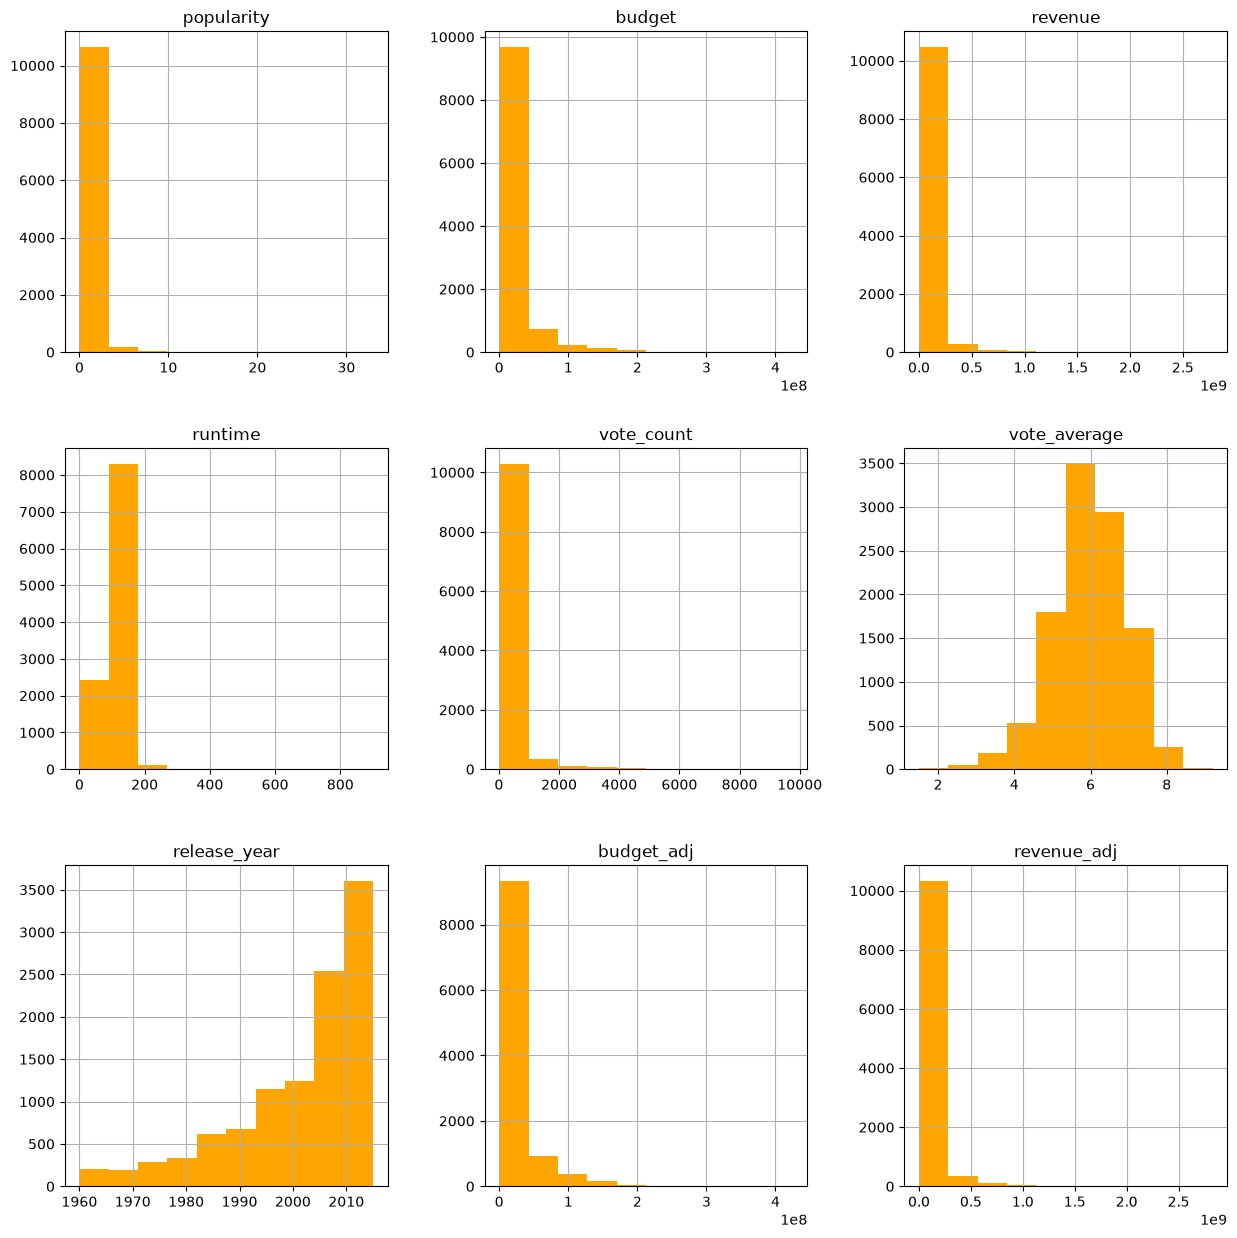

In [4]:
# show the histogram of the data
tmdb_df.drop(columns='id').hist(figsize=(15, 15), color='orange')
plt.show()

Vote average is a normal distribution centered around ~6. 

Popularity, budget/budget_adj, revenue/revenue_adj, and vote_count are right-skewed.

Runtime is also right-skewed, but most movies cluster around ~100 minutes.

### Checking the raw file

The histograms show the shape. Next I check what is missing, what is repeated, and where a 0 is not a real number.


In [5]:
# missing values, and how many different values each column has
print("Missing values")
print(tmdb_df.isnull().sum().to_string())
print("\nUnique values")
print(tmdb_df.nunique().to_string())


Missing values
id                         0
imdb_id                   10
popularity                 0
budget                     0
revenue                    0
original_title             0
cast                      76
homepage                7930
director                  44
tagline                 2824
keywords                1493
overview                   4
runtime                    0
genres                    23
production_companies    1030
release_date               0
vote_count                 0
vote_average               0
release_year               0
budget_adj                 0
revenue_adj                0

Unique values
id                      10865
imdb_id                 10855
popularity              10814
budget                    557
revenue                  4702
original_title          10571
cast                    10719
homepage                 2896
director                 5067
tagline                  7997
keywords                 8804
overview                10847
r

In [6]:
# last rows
tmdb_df.tail()


,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
10861,21,tt0060371,0.080598,0,0,The Endless Summer,Michael Hynson|Robert August|Lord 'Tally Ho' B...,NaN,Bruce Brown,NaN,...,"The Endless Summer, by Bruce Brown, is one of ...",95,Documentary,Bruce Brown Films,6/15/66,11,7.4,1966,0.000000,0.0
10862,20379,tt0060472,0.065543,0,0,Grand Prix,James Garner|Eva Marie Saint|Yves Montand|Tosh...,NaN,John Frankenheimer,Cinerama sweeps YOU into a drama of speed and ...,...,Grand Prix driver Pete Aron is fired by his te...,176,Action|Adventure|Drama,Cherokee Productions|Joel Productions|Douglas ...,12/21/66,20,5.7,1966,0.000000,0.0
10863,39768,tt0060161,0.065141,0,0,Beregis Avtomobilya,Innokentiy Smoktunovskiy|Oleg Efremov|Georgi Z...,NaN,Eldar Ryazanov,NaN,...,An insurance agent who moonlights as a carthie...,94,Mystery|Comedy,Mosfilm,1/1/66,11,6.5,1966,0.000000,0.0
10864,21449,tt0061177,0.064317,0,0,"What's Up, Tiger Lily?",Tatsuya Mihashi|Akiko Wakabayashi|Mie Hama|Joh...,NaN,Woody Allen,WOODY ALLEN STRIKES BACK!,...,"In comic Woody Allen's film debut, he took the...",80,Action|Comedy,Benedict Pictures Corp.,11/2/66,22,5.4,1966,0.000000,0.0
10865,22293,tt0060666,0.035919,19000,0,Manos: The Hands of Fate,Harold P. Warren|Tom Neyman|John Reynolds|Dian...,NaN,Harold P. Warren,It's Shocking! It's Beyond Your Imagination!,...,A family gets lost on the road and stumbles up...,74,Horror,Norm-Iris,11/15/66,15,1.5,1966,127642.279154,0.0


In [7]:
# a few random rows, same ones each run
tmdb_df.sample(5, random_state=1)


,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
921,244268,tt2639344,0.451125,0,2262223,Love Is Strange,John Lithgow|Alfred Molina|Marisa Tomei|Darren...,http://www.sonyclassics.com/loveisstrange/,Ira Sachs,NaN,...,"After 39 years together, Ben and George finall...",98,Drama,Parts and Labor|Mm...Buttered Panini Productio...,2/7/14,68,6.4,2014,0.000000e+00,2.083713e+06
10824,2525,tt0060164,0.533292,18000000,0,The Bible: In the Beginning...,Michael Parks|Ulla Bergryd|Richard Harris|Fran...,NaN,John Huston,The unforgettable adventure of Man from the Cr...,...,Extravagant production of the first part of th...,174,Drama,Seven Arts Productions|Dino de Laurentiis Cine...,9/28/66,18,5.8,1966,1.209243e+08,0.000000e+00
2331,38033,tt1148200,0.150336,0,0,Chain Letter,Nikki Reed|Keith David|Brad Dourif|Betsy Russe...,NaN,Deon Taylor,"If you don't forward it, you die.",...,Six friends receive a mysterious chain letter ...,96,Horror|Thriller,Tiger Tail Entertainment|Deon Taylor Enterprises,10/1/10,15,3.8,2010,0.000000e+00,0.000000e+00
2354,57011,tt1592503,0.107503,0,0,Alien vs. Ninja,Mika Hijii|Ben Hiura|ShÃ»ji Kashiwabara|Masano...,NaN,Seiji Chiba,Only one can win.,...,"A band of ninja warriors, led by an Iga Ninja ...",81,Horror|Action|Thriller|Science Fiction,Nikkatsu|North CKY,7/3/10,17,3.5,2010,0.000000e+00,0.000000e+00
2740,14034,tt0161083,0.455072,45000000,0,What's the Worst That Could Happen?,Martin Lawrence|Danny DeVito|John Leguizamo|Gl...,NaN,Sam Weisman,It takes a thief to nail a crook.,...,Thief Kevin Caffery attempts to rob from the h...,94,Action|Comedy,Metro-Goldwyn-Mayer (MGM),5/31/01,31,5.1,2001,5.541697e+07,0.000000e+00


In [8]:
# movies per year. later years have more
print(tmdb_df['release_year'].value_counts().sort_index().to_string())

# 0 here means not reported
print("\nbudget_adj == 0:", tmdb_df.loc[tmdb_df['budget_adj'] == 0].shape[0])
print("revenue_adj == 0:", tmdb_df.loc[tmdb_df['revenue_adj'] == 0].shape[0])
print("runtime == 0:", tmdb_df.loc[tmdb_df['runtime'] == 0].shape[0])

# both copies of the TEKKEN row
dupe_rows = tmdb_df.loc[tmdb_df.duplicated(keep=False)]
print(tmdb_df.iloc[dupe_rows.index[0]:dupe_rows.index[-1] + 1][
    ['original_title', 'release_year', 'runtime', 'budget_adj', 'revenue_adj']
].to_string())


release_year
1960     32
1961     31
1962     32
1963     34
1964     42
1965     35
1966     46
1967     40
1968     39
1969     31
1970     41
1971     55
1972     40
1973     55
1974     47
1975     44
1976     47
1977     57
1978     65
1979     57
1980     78
1981     82
1982     81
1983     80
1984    105
1985    109
1986    121
1987    125
1988    145
1989    137
1990    132
1991    133
1992    133
1993    178
1994    184
1995    175
1996    204
1997    192
1998    210
1999    224
2000    227
2001    242
2002    266
2003    281
2004    307
2005    364
2006    408
2007    438
2008    496
2009    533
2010    490
2011    540
2012    588
2013    659
2014    700
2015    629

budget_adj == 0: 5696
revenue_adj == 0: 6016
runtime == 0: 31
     original_title  release_year  runtime  budget_adj  revenue_adj
2089         TEKKEN          2010       92  30000000.0     967000.0
2090         TEKKEN          2010       92  30000000.0     967000.0


`homepage`, `tagline`, `keywords`, and `production_companies` are missing a lot. `cast`, `director`, `genres`, `overview`, and `imdb_id` have a few missing too. The columns I use later, `popularity`, `vote_average`, `runtime`, `release_year`, `budget_adj`, and `revenue_adj`, have no missing values. `id` has 10865 different values in 10866 rows. That is the duplicated movie.

`tail` and `sample` are so I am not only looking at the first 10 rows. `release_year` goes from 1960 to 2015. 1960 has 32 movies and 2014 has 700, so later years have a lot more movies. That is why the year correlation can sit near zero.

About half of `budget_adj` and `revenue_adj` are 0, and 31 runtimes are 0. I keep those zeros in the main table and only drop them for the question that needs the column. The only full duplicate is TEKKEN (2010). Both copies are the rows above.



### Data Cleaning
 

From the checks above, the 0 rows stay in the table until a question needs that column. Let's drop the columns we don't need for the questions: `keywords`, `tagline`, `production_companies`, `homepage`, `director`, `cast`, `overview`, `genres`, `release_date`, `id`, `imdb_id`, `budget`, and `revenue`. We keep `original_title` so we can examine outliers and see what they are. `release_year` is enough, so we drop `release_date`. For budget and revenue we use the adjusted columns, `budget_adj` and `revenue_adj`, in 2010 dollars. There is also one duplicated row, TEKKEN from 2010, so I drop that too.

In [9]:
# Let's drop text columns that we will not use for answering the questions.
# We will keep original_title so we can examine outliers and see what they are.
# release_year is enough so we can drop release_date.
# We also don't need imdb_id, id.
# For revenue and budget, we will use adjusted values so we can drop the unadjusted columns.
unused_columns = [
    'keywords',
    'tagline',
    'production_companies',
    'homepage',
    'director',
    'cast',
    'overview',
    'release_date',
    'genres',
    'imdb_id',
    'id',
    'revenue',
    'budget'
]
tmdb_df = tmdb_df.drop(columns=unused_columns)
tmdb_df.head()


,popularity,original_title,runtime,vote_count,vote_average,release_year,budget_adj,revenue_adj
0,32.985763,Jurassic World,124,5562,6.5,2015,1.379999e+08,1.392446e+09
1,28.419936,Mad Max: Fury Road,120,6185,7.1,2015,1.379999e+08,3.481613e+08
2,13.112507,Insurgent,119,2480,6.3,2015,1.012000e+08,2.716190e+08
3,11.173104,Star Wars: The Force Awakens,136,5292,7.5,2015,1.839999e+08,1.902723e+09
4,9.335014,Furious 7,137,2947,7.3,2015,1.747999e+08,1.385749e+09


In [10]:
# check the columns
tmdb_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10866 entries, 0 to 10865
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   popularity      10866 non-null  float64
 1   original_title  10866 non-null  str    
 2   runtime         10866 non-null  int64  
 3   vote_count      10866 non-null  int64  
 4   vote_average    10866 non-null  float64
 5   release_year    10866 non-null  int64  
 6   budget_adj      10866 non-null  float64
 7   revenue_adj     10866 non-null  float64
dtypes: float64(4), int64(3), str(1)
memory usage: 679.3 KB


In [11]:
# Check for duplicates.
print(f"Rows before dropping duplicates: {len(tmdb_df)}")
print(f"Duplicate rows: {tmdb_df.duplicated().sum()}")
tmdb_df = tmdb_df.drop_duplicates()
print(f"Rows after dropping the duplicate: {len(tmdb_df)}")


Rows before dropping duplicates: 10866
Duplicate rows: 1
Rows after dropping the duplicate: 10865


In [12]:
# We also need to fix the codepage mismatch that the data file has for the title column
# based on the suggestions here: https://stackoverflow.com/questions/23326531/how-to-decode-cp1252-string
def codepage_mismatch(text):
    try:
        return text.encode('cp1252').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text

tmdb_df['original_title'] = tmdb_df['original_title'].map(codepage_mismatch)

In [13]:
# We also need to create dfs cleaned of the 0 budget rows for the fists question:
df_no_zero_budget = tmdb_df[tmdb_df['budget_adj'] > 0]
print(f"Rows with budget > 0: {df_no_zero_budget['budget_adj'].count()}")

df_no_zero_revenue_budget = tmdb_df[(tmdb_df['revenue_adj'] > 0) & (tmdb_df['budget_adj'] > 0)]
print(f"Rows with revenue > 0 and budget > 0: {df_no_zero_revenue_budget['revenue_adj'].count()}")

# And a df with no runtime droppped rows
df_with_runtime = tmdb_df[tmdb_df['runtime'] > 0]
print(f"Rows with runtime > 0: {df_with_runtime['runtime'].count()}")

# And last not least, a df with no revenue dropped rows
df_no_zero_revenue = tmdb_df[tmdb_df['revenue_adj'] > 0]
print(f"Rows with revenue > 0: {df_no_zero_revenue['revenue_adj'].count()}")


Rows with budget > 0: 5169
Rows with revenue > 0 and budget > 0: 3854
Rows with runtime > 0: 10834
Rows with revenue > 0: 4849


df_no_zero_budget drops rows with a zero budget_adj. We need it for budget versus popularity and vote average. df_no_zero_revenue_budget drops rows with a zero budget_adj or a zero revenue_adj. We need that one for budget versus revenue.

df_with_runtime drops the 31 rows whose runtime is 0. We need it for runtime versus popularity and vote average.

df_no_zero_revenue drops rows with a zero revenue_adj. We need that one for release year versus revenue.
 

<a id='eda'></a>
## Exploratory Data Analysis

In [14]:
# Helper function to compare one column with another
# with correlation, histogram for each column, then a scatter plot with a trend line.
def compare_columns(data, title, x_column, y_column, x_label, y_label, log_scale_x=False):
    x_axis_label = f'{x_label} (log scale)' if log_scale_x else x_label

    print("\n\n------------------------------------------------------------------------------------------------")
    print(title)
    print("------------------------------------------------------------------------------------------------\n")

    correlation = numpy.corrcoef(data[x_column], data[y_column])[0, 1]
    print(f'Correlation between {x_label} and {y_label}: {correlation:.3f}')

    # Summary and histogram for each column 
    print(data[[x_column, y_column]].describe())

    data[x_column].plot(kind='hist', bins=40, color='orange', figsize=(8, 4))
    plt.title(f'Distribution of {x_label}')
    plt.xlabel(x_label)
    plt.ylabel('Number of movies')
    plt.show()

    data[y_column].plot(kind='hist', bins=40, color='darkgray', figsize=(8, 4))
    plt.title(f'Distribution of {y_label}')
    plt.xlabel(y_label)
    plt.ylabel('Number of movies')
    plt.show()

    # Relationship between the TWO columns
    plt.figure(figsize=(8, 4))
    plt.scatter(data[x_column], data[y_column], alpha=0.25, s=12, color='orange', label='Movies')
    if log_scale_x:
        plt.xscale('log')

    # trend line, so the slope is easier to see
    x_values = data[x_column].to_numpy()
    y_values = data[y_column].to_numpy()
    slope, intercept = numpy.polyfit(x_values, y_values, 1)
    if log_scale_x:
        x_line = numpy.logspace(numpy.log10(x_values.min()), numpy.log10(x_values.max()), 200)
    else:
        x_line = numpy.linspace(x_values.min(), x_values.max(), 200)
    plt.plot(x_line, slope * x_line + intercept, color='steelblue', linewidth=2, label='Trend line')

    plt.title(f'{x_label} and {y_label}')
    plt.xlabel(x_axis_label)
    plt.ylabel(y_label)
    plt.legend()
    plt.show()

    return correlation


### How does budget (adjusted) relate to popularity and to vote average?



------------------------------------------------------------------------------------------------
Popularity vs. budget
------------------------------------------------------------------------------------------------

Correlation between Budget in 2010 dollars and Popularity: 0.435
         budget_adj   popularity
count  5.169000e+03  5169.000000
mean   3.688907e+07     0.992400
std    4.196096e+07     1.329262
min    9.210911e-01     0.001117
25%    8.102293e+06     0.347958
50%    2.271505e+07     0.624024
75%    5.008384e+07     1.152417
max    4.250000e+08    32.985763


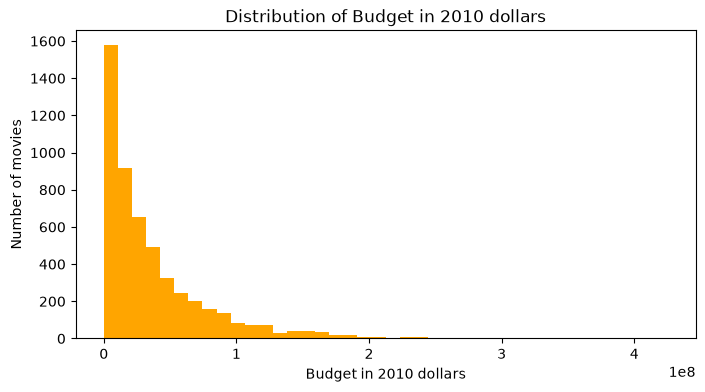

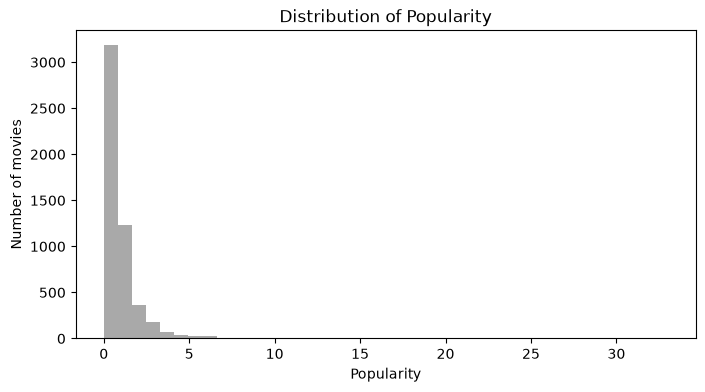

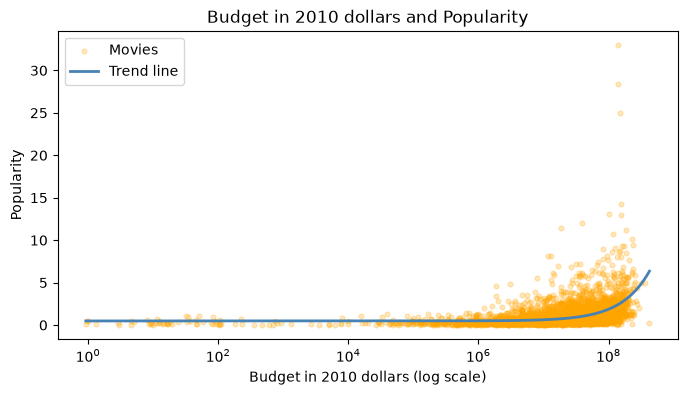

np.float64(0.4353363637164347)

In [15]:
compare_columns(
    df_no_zero_budget,
    'Popularity vs. budget',
    'budget_adj',
    'popularity',
    log_scale_x=True,
    x_label='Budget in 2010 dollars',
    y_label='Popularity',
)



------------------------------------------------------------------------------------------------
Vote average vs. budget
------------------------------------------------------------------------------------------------

Correlation between Budget in 2010 dollars and Vote average: 0.112
         budget_adj  vote_average
count  5.169000e+03   5169.000000
mean   3.688907e+07      6.032308
std    4.196096e+07      0.884125
min    9.210911e-01      1.500000
25%    8.102293e+06      5.500000
50%    2.271505e+07      6.100000
75%    5.008384e+07      6.600000
max    4.250000e+08      8.400000


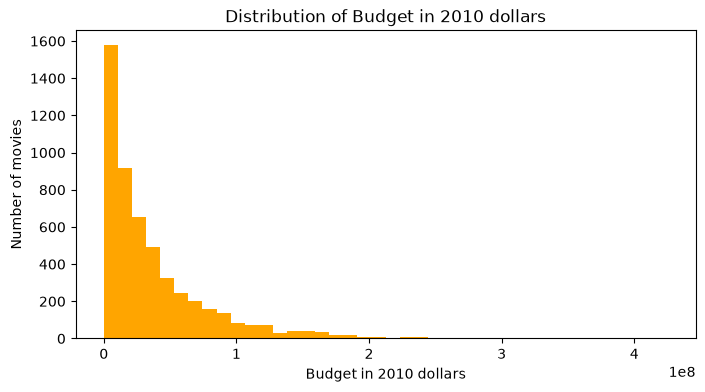

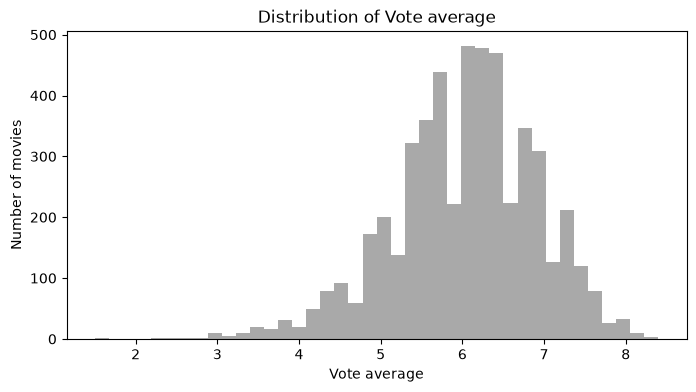

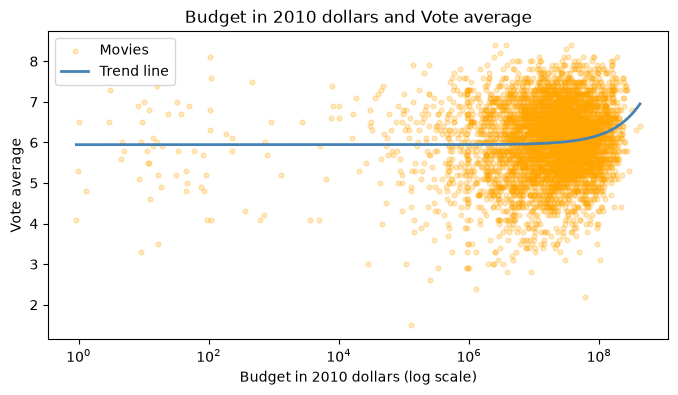

np.float64(0.11222599460414213)

In [16]:
compare_columns(
    df_no_zero_budget,
    'Vote average vs. budget',
    'budget_adj',
    'vote_average',
    log_scale_x=True,
    x_label='Budget in 2010 dollars',
    y_label='Vote average',
)

Reported budgets are piled at the lower end. Among the 5169 movies with a budget, the median is about $23 million and the mean is about $37 million.

A higher budget seems to be moderately associated with higher popularity. The Pearson correlation is 0.44. Both histograms are right-skewed. The scatter shows movies with larger budgets plotted toward higher popularity.

Vote average barely changes with budget. The correlation is 0.11. The vote-average histogram is roughly centered around 6 with a normal distribution. The scatter does not show a higher vote average at higher budgets. A larger budget is not associated with a higher rating.

The mean budget is higher than the median because a few very expensive movies pull it up. That is the long tail on the budget histogram. Popularity is piled near the bottom too. The trend line on the popularity scatter goes up, same as the 0.44 correlation. The vote average histogram is the hump around 6 again, and that trend line is almost flat, same as the 0.11.



---

### How does budget (adjusted) relate to revenue (adjusted)?



------------------------------------------------------------------------------------------------
Revenue vs. budget
------------------------------------------------------------------------------------------------

Correlation between Budget in 2010 dollars and Revenue in 2010 dollars: 0.570
         budget_adj   revenue_adj
count  3.854000e+03  3.854000e+03
mean   4.423999e+07  1.370647e+08
std    4.480925e+07  2.161114e+08
min    9.693980e-01  2.370705e+00
25%    1.309053e+07  1.835735e+07
50%    3.001611e+07  6.173068e+07
75%    6.061307e+07  1.632577e+08
max    4.250000e+08  2.827124e+09


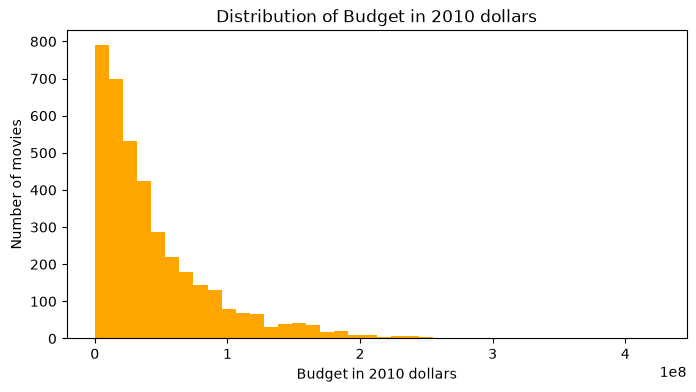

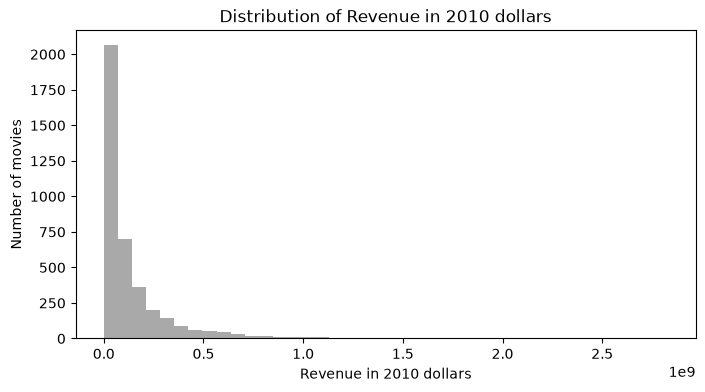

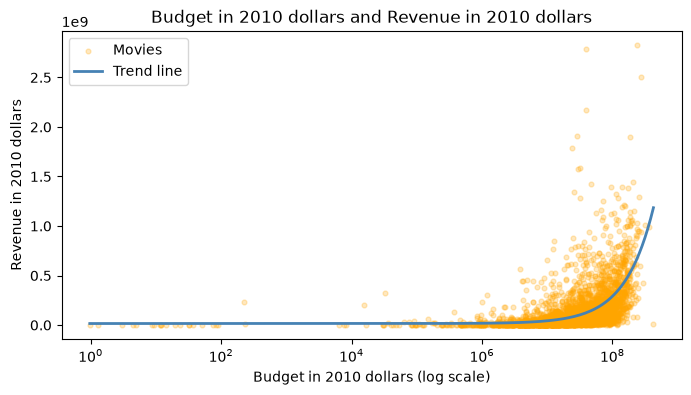

np.float64(0.5704510195812404)

In [17]:
compare_columns(
    df_no_zero_revenue_budget,
    'Revenue vs. budget',
    'budget_adj',
    'revenue_adj',
    log_scale_x=True,
    x_label='Budget in 2010 dollars',
    y_label='Revenue in 2010 dollars',
)

A higher budget seems moderately associated with higher revenue. Among the 3854 movies with both amounts reported, the Pearson correlation is 0.57. Both histograms are right-skewed, and the scatter trends upward.

The two histograms match. Most movies are at the low end of both budget and revenue, with a few very large amounts in the tail. The trend line goes up. 0.57 is the strongest correlation of the four questions, so the two amounts move together.



---

### How does runtime relate to popularity and to vote average?



------------------------------------------------------------------------------------------------
Popularity vs. runtime
------------------------------------------------------------------------------------------------

Correlation between Runtime (minutes) and Popularity: 0.137
            runtime    popularity
count  10834.000000  10834.000000
mean     102.363855      0.647762
std       30.948225      1.001204
min        2.000000      0.000065
25%       90.000000      0.208536
50%       99.000000      0.384691
75%      112.000000      0.715448
max      900.000000     32.985763


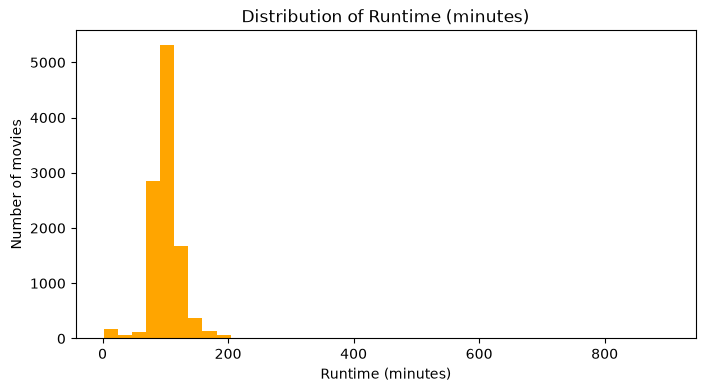

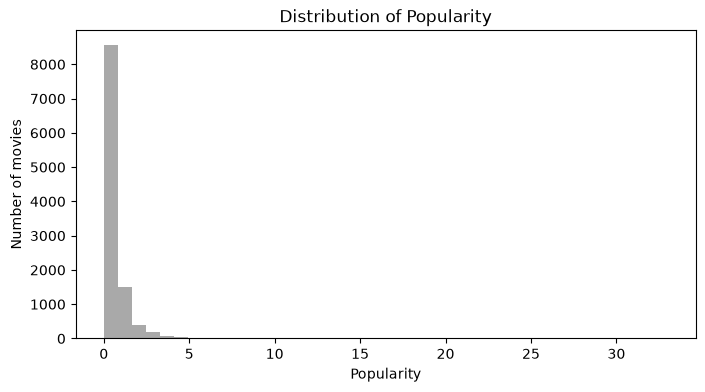

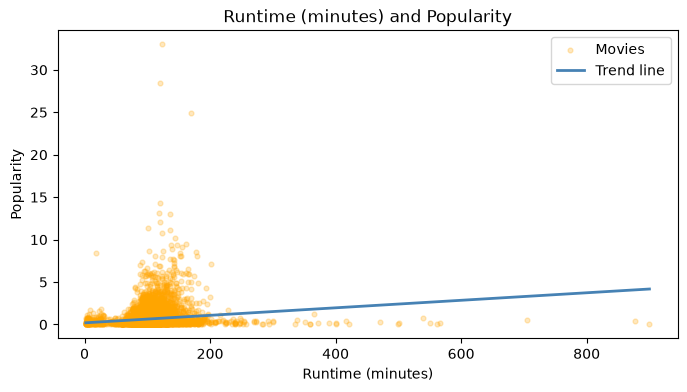

np.float64(0.1369005685920793)

In [18]:
compare_columns(
    df_with_runtime,
    'Popularity vs. runtime',
    'runtime',
    'popularity',
    x_label='Runtime (minutes)',
    y_label='Popularity',
)


In [19]:
# let's examine that 120 minutes peak in the scatter
around_two_hours = df_with_runtime[df_with_runtime['runtime'].between(110, 130)]
around_two_hours.nlargest(10, 'popularity')[['original_title', 'runtime', 'popularity', 'release_year']]

,original_title,runtime,popularity,release_year
0,Jurassic World,124,32.985763,2015
1,Mad Max: Fury Road,120,28.419936,2015
630,Guardians of the Galaxy,121,14.311205,2014
2,Insurgent,119,13.112507,2015
1329,Star Wars,121,12.037933,1977
633,The Hunger Games: Mockingjay - Part 1,123,10.739009,2014
6,Terminator Genisys,125,8.654359,2015
636,The Imitation Game,113,8.110711,2014
3372,Captain America: The First Avenger,124,7.959228,2011
637,The Maze Runner,113,7.137273,2014




------------------------------------------------------------------------------------------------
Vote average vs. runtime
------------------------------------------------------------------------------------------------

Correlation between Runtime (minutes) and Vote average: 0.155
            runtime  vote_average
count  10834.000000  10834.000000
mean     102.363855      5.976343
std       30.948225      0.935047
min        2.000000      1.500000
25%       90.000000      5.400000
50%       99.000000      6.000000
75%      112.000000      6.600000
max      900.000000      9.200000


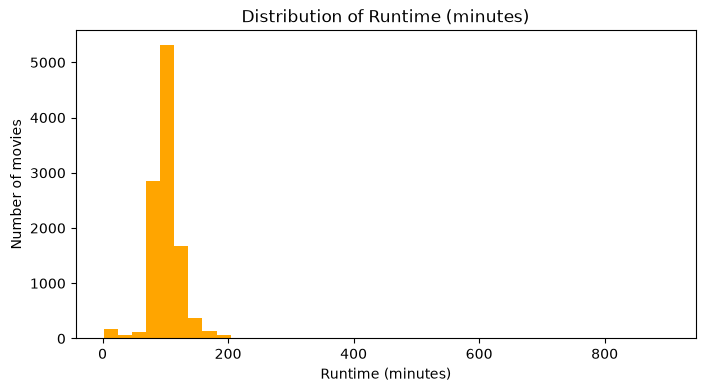

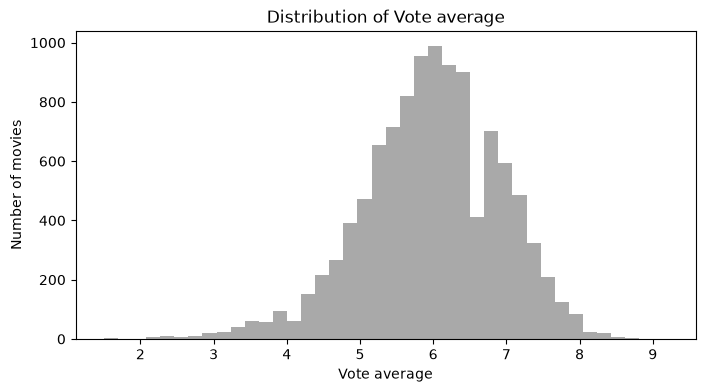

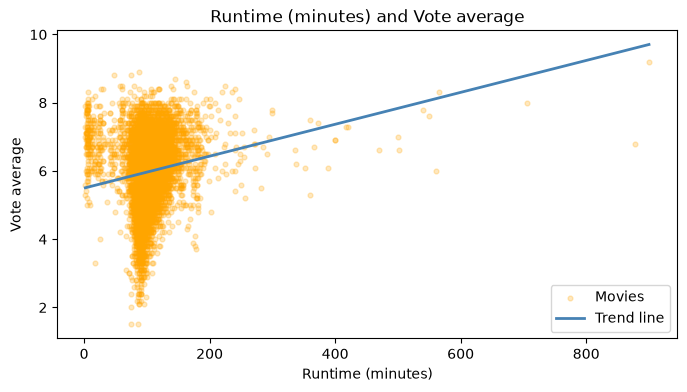

np.float64(0.15477467159967231)

In [20]:
compare_columns(
    df_with_runtime,
    'Vote average vs. runtime',
    'runtime',
    'vote_average',
    x_label='Runtime (minutes)',
    y_label='Vote average',
)

Runtime has a weak association with both outcomes. Among the 10834 movies with a runtime, the correlation with popularity is 0.14 and the correlation with vote average is 0.15. 

The runtime histogram is clustered around about 100 minutes, with a few runtimes of several hundred minutes. There is a peak around 120 minutes for the popularity visible in the scatter, most likely the result of popular movies typically sitting in that runtime like Jurrassic World, Mad Max: Fury Road etc.

The runtime histogram is not a long tail like the money columns. Popularity is still piled near zero, so the trend line only goes up a little, same as the 0.14 correlation. Those tall points near 120 minutes are a few blockbuster movies, not the typical one. The vote average histogram stays centered around 6, and that trend line is almost flat.



---

### How does release year relate to revenue?



------------------------------------------------------------------------------------------------
Revenue vs. release year
------------------------------------------------------------------------------------------------

Correlation between Release year and Revenue in 2010 dollars: -0.099
       release_year   revenue_adj
count   4849.000000  4.849000e+03
mean    2000.919777  1.151009e+08
std       11.569650  1.988557e+08
min     1960.000000  2.370705e+00
25%     1994.000000  1.046585e+07
50%     2004.000000  4.395666e+07
75%     2010.000000  1.316482e+08
max     2015.000000  2.827124e+09


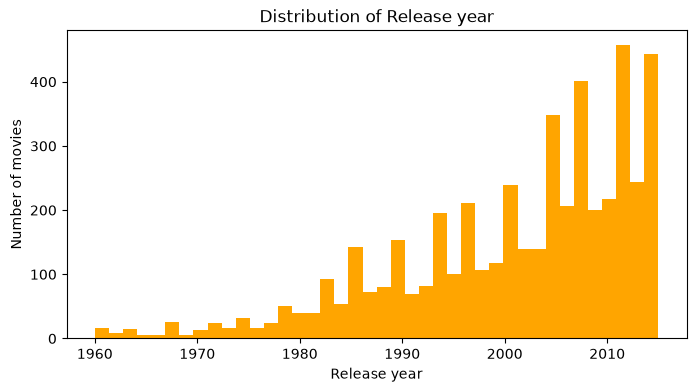

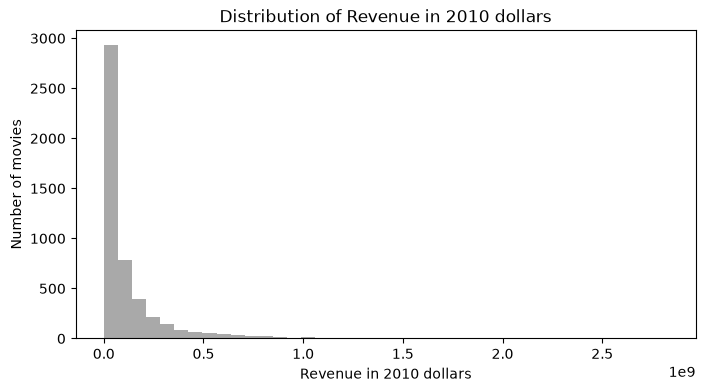

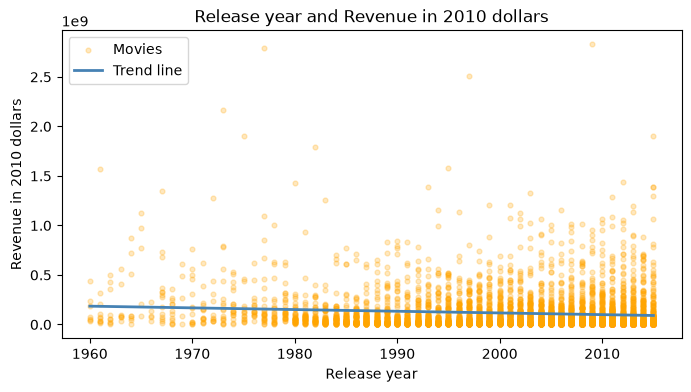

np.float64(-0.09944655563517754)

In [21]:
compare_columns(
    df_no_zero_revenue,
    'Revenue vs. release year',
    'release_year',
    'revenue_adj',
    x_label='Release year',
    y_label='Revenue in 2010 dollars',
)

Release year is barely associated with revenue in 2010 dollars. Among the 4849 movies with a reported revenue, the correlation is -0.10. The scatter does not show a rise or fall in revenue, in 2010 dollars, from 1960 to 2015. Later years also contain many more movies, so the year histogram is denser on the right. 1960 has 32 movies and 2014 has 700.

The revenue histogram is piled at the low end, with a few very large amounts above it. The trend line is almost flat and tilts down a bit, same as the -0.10 correlation.


<a id='conclusions'></a>
## Conclusions

A higher budget seems to be moderately associated with higher popularity. Among the 5169 movies with a budget, the Pearson correlation is 0.44. Vote average barely changes with budget. The correlation is 0.11. A larger budget is not associated with a higher rating.

A higher budget seems moderately associated with higher revenue. Among the 3854 movies with both amounts reported, the Pearson correlation is 0.57, and the scatter trends upward.

Runtime has a weak association with both outcomes. Among the 10834 movies with a runtime, the correlation with popularity is 0.14 and the correlation with vote average is 0.15. The runtime histogram is clustered around about 100 minutes, with a few runtimes of several hundred minutes. There is a peak around 120 minutes for the popularity visible in the scatter, most likely the result of popular movies typically sitting in that runtime like Jurrassic World, Mad Max: Fury Road etc.

Release year is barely associated with revenue in 2010 dollars. Among the 4849 movies with a reported revenue, the correlation is -0.10. The scatter does not show a rise or fall in revenue, in 2010 dollars, from 1960 to 2015. Later years also contain many more movies, so the year histogram is denser on the right.

This does not show that spending more causes a movie to become more popular or better rated, or to earn more revenue, or that newer movies earn less or more.

Each comparison used a correlation, a histogram of each column, and a scatter. I added a trend line on the scatter. It goes the same way as the correlation. Rows with a zero budget, revenue, or runtime were left out only for the question that needed that column.

One limitation is that many movies have a zero budget or a zero revenue. I left those zero budget/revenue rows out, so the budget and revenue results are only for movies that have an amount filled in. Popularity is also higher for movies people were looking at when this file was collected. The highest points, like Jurrassic World, Mad Max: Fury Road etc., are recent titles.

Later years also contain many more movies, so the year histogram is denser on the right. Next I would look at the typical revenue for each year, not just the correlation. The correlation does not show whether a typical movie earns less.



In [22]:
# Running this cell will execute a bash command to convert this notebook to an .html file
!python -m nbconvert --to html Investigate_a_Dataset.ipynb

[NbConvertApp] Converting notebook Investigate_a_Dataset.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 19 image(s).
[NbConvertApp] Writing 1108801 bytes to Investigate_a_Dataset.html
